In [10]:

!pip -q install vaderSentiment

import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("Sentiment Analysis Project Started!")


Sentiment Analysis Project Started!


In [11]:

reviews = [
    "This phone is amazing!",
    "I love this product.",
    "Excellent quality and great value.",
    "The phone is okay.",
    "It works as expected.",
    "Nothing special about it.",
    "Very bad battery life.",
    "Terrible product and poor quality.",
    "I am disappointed with this purchase.",
    "The product is awful."
]

df = pd.DataFrame({"Review": reviews})

df


,Review
0,This phone is amazing!
1,I love this product.
2,Excellent quality and great value.
3,The phone is okay.
4,It works as expected.
5,Nothing special about it.
6,Very bad battery life.
7,Terrible product and poor quality.
8,I am disappointed with this purchase.
9,The product is awful.


In [12]:

def get_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["Sentiment"] = df["Review"].apply(get_sentiment)

display(df)


,Review,Sentiment
0,This phone is amazing!,Positive
1,I love this product.,Positive
2,Excellent quality and great value.,Positive
3,The phone is okay.,Positive
4,It works as expected.,Neutral
5,Nothing special about it.,Negative
6,Very bad battery life.,Negative
7,Terrible product and poor quality.,Negative
8,I am disappointed with this purchase.,Negative
9,The product is awful.,Negative


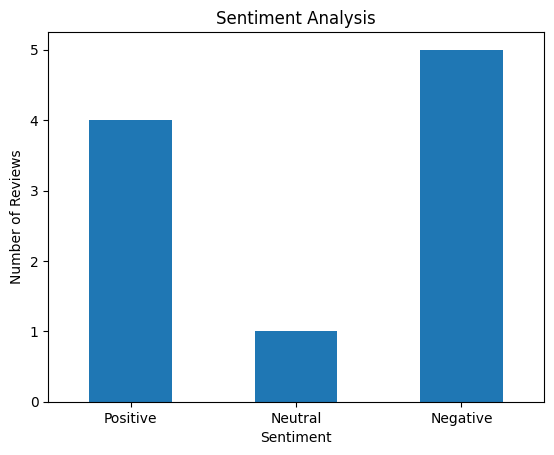

In [13]:

counts = df["Sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"],
    fill_value=0
)

counts.plot(kind="bar", rot=0)

plt.title("Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


In [14]:

# Step 6: Emotion Detection using Keywords

emotion_lexicon = {
    "Joy": ["love", "happy", "amazing", "excellent", "great"],
    "Anger": ["angry", "hate", "furious", "annoyed"],
    "Sadness": ["sad", "disappointed", "unhappy"],
    "Fear": ["afraid", "scared", "worried", "anxious"],
    "Surprise": ["surprised", "unexpected", "shocked"],
    "Disgust": ["terrible", "awful", "gross"]
}

def detect_emotion(text):
    words = set(text.lower().replace("!", "").replace(".", "").replace(",", "").split())

    emotions_found = []

    for emotion, keywords in emotion_lexicon.items():
        if any(word in words for word in keywords):
            emotions_found.append(emotion)

    if emotions_found:
        return ", ".join(emotions_found)
    else:
        return "No keyword match"

df["Emotion"] = df["Review"].apply(detect_emotion)

display(df)


,Review,Sentiment,Emotion
0,This phone is amazing!,Positive,Joy
1,I love this product.,Positive,Joy
2,Excellent quality and great value.,Positive,Joy
3,The phone is okay.,Positive,No keyword match
4,It works as expected.,Neutral,No keyword match
5,Nothing special about it.,Negative,No keyword match
6,Very bad battery life.,Negative,No keyword match
7,Terrible product and poor quality.,Negative,Disgust
8,I am disappointed with this purchase.,Negative,Sadness
9,The product is awful.,Negative,Disgust


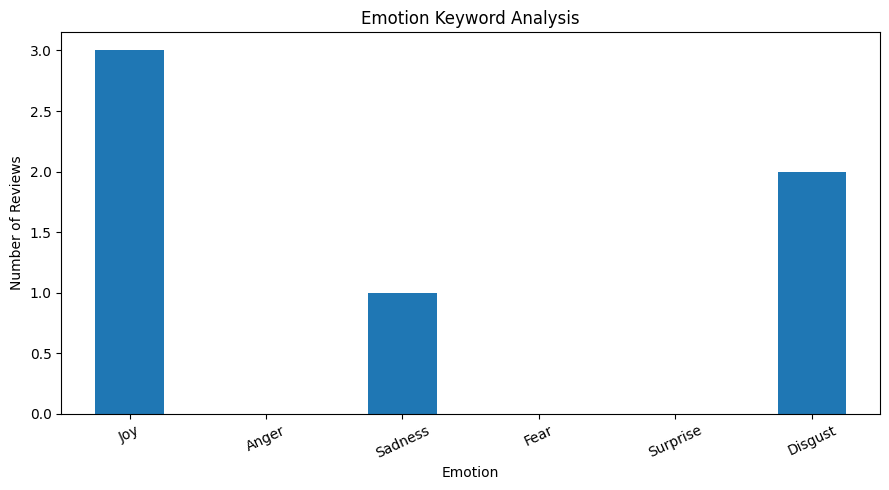

In [15]:

# Step 7: Emotion Graph

emotion_counts = {}

for emotion in emotion_lexicon:
    emotion_counts[emotion] = sum(
        emotion in result.split(", ")
        for result in df["Emotion"]
        if result != "No keyword match"
    )

emotion_series = pd.Series(emotion_counts)

emotion_series.plot(kind="bar", figsize=(9, 5), rot=25)

plt.title("Emotion Keyword Analysis")
plt.xlabel("Emotion")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


In [17]:

# STEP 8: Final Insights & Conclusion

print("===== SENTIMENT ANALYSIS INSIGHTS =====")

# Sentiment summary
sentiment_counts = df["Sentiment"].value_counts()

print("\n1. Sentiment Summary:")
print(sentiment_counts)

# Most common sentiment
if not sentiment_counts.empty:
    print("\n2. Most Common Sentiment:",
          sentiment_counts.idxmax())

# Emotion summary
print("\n3. Emotion Summary:")
print(df["Emotion"].value_counts())

# Business Insights
print("\n4. Business Insights:")

if "Positive" in sentiment_counts.index:
    print("- Positive reviews show customer satisfaction.")

if "Negative" in sentiment_counts.index:
    print("- Negative reviews can highlight areas for improvement.")

if "Neutral" in sentiment_counts.index:
    print("- Neutral reviews may provide useful product feedback.")

print("\n5. Conclusion:")
print("Sentiment analysis helps businesses understand")
print("customer opinions and improve products and services.")


===== SENTIMENT ANALYSIS INSIGHTS =====

1. Sentiment Summary:
Sentiment
Negative    5
Positive    4
Neutral     1
Name: count, dtype: int64

2. Most Common Sentiment: Negative

3. Emotion Summary:
Emotion
No keyword match    4
Joy                 3
Disgust             2
Sadness             1
Name: count, dtype: int64

4. Business Insights:
- Positive reviews show customer satisfaction.
- Negative reviews can highlight areas for improvement.
- Neutral reviews may provide useful product feedback.

5. Conclusion:
Sentiment analysis helps businesses understand
customer opinions and improve products and services.
